In [21]:
import os
import lmdb
import pickle
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# MultiGenSe

- read image names

In [2]:
fd = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/test_data/multisenge'
fp_img = os.path.join(fd, 's2')
fp_label = os.path.join(fd, 'ground_reference')
fns_img = os.listdir(fp_img)    
fns_lbl = os.listdir(fp_label)
len(fns_img), len(fns_lbl)

(72033, 8157)

- pair label and image names

In [14]:
name_dict = {k:[] for k in fns_lbl}
dates = []
for fn in fns_img:
    fn_split = fn.split('_')
    fn_lbl = fn_split[0] + '_GR_' + fn_split[3] + '_' + fn_split[4]
    name_dict[fn_lbl].append(fn_split[1]) 
    dates.append(fn_split[1])
all_dates = np.unique(dates)
len(all_dates), all_dates

(52,
 array(['20200105', '20200106', '20200115', '20200116', '20200121',
        '20200207', '20200315', '20200318', '20200325', '20200402',
        '20200404', '20200407', '20200414', '20200417', '20200422',
        '20200507', '20200517', '20200519', '20200527', '20200529',
        '20200530', '20200601', '20200623', '20200624', '20200721',
        '20200723', '20200729', '20200731', '20200805', '20200807',
        '20200808', '20200812', '20200820', '20200904', '20200909',
        '20200911', '20200912', '20200914', '20200916', '20200917',
        '20200919', '20200921', '20200922', '20201031', '20201105',
        '20201106', '20201118', '20201121', '20201126', '20201128',
        '20201210', '20201218'], dtype='<U8'))

- check whether each label has at least one image paired

In [11]:
for k, v in name_dict.items():
    if len(v) == 0: print(k)

- randomly select images from jun-sep

In [15]:
selected_pair = {}
n_nod = 0
for k, v in name_dict.items():
    dlist = []
    for f in v:
        if f[:6] in ['202006', '202007', '202008', '202009']:
            dlist.append(f)
    if len(dlist) > 0:
        d = np.random.choice(dlist)
    else:
        d = np.random.choice(v)
        n_nod += 1
    split_k = k.split('_')
    selected_pair[k] = f'{split_k[0]}_{d}_S2_{split_k[2]}_{split_k[3]}'
n_nod

0

- test bands: 10 in total - B2, 3, 4 ,5, 6, 7, 8, 8A, 11, 12

In [20]:
imgs = []
for k, v in selected_pair.items():
    fp = os.path.join(fp_img, v)
    with rasterio.open(fp) as src:
        imgs.append(src.read())
imgs = np.stack(imgs,axis=-1)
print(imgs.shape)
np.mean(imgs, axis=(1,2,3)), np.std(imgs, axis=(1,2,3))

(10, 256, 256, 8157)


(array([ 507.44121799,  794.43579126,  917.53047887, 1280.02549648,
        2353.54860661, 2784.10044086, 2906.22536837, 3118.75860355,
        2458.14194296, 1530.71782411]),
 array([ 429.50932716,  538.1354021 ,  839.24643053,  759.41613426,
         619.05321479,  746.88374152,  801.34388759,  799.21976488,
        1087.54322848,  974.40837274]))

In [27]:
lbls = []
for k, v in selected_pair.items():
    fp = os.path.join(fp_label, k)
    with rasterio.open(fp) as src:
        lbls.append(src.read())
lbls = np.stack(lbls, axis=-1)
print(lbls.shape)
np.unique(lbls)

(1, 256, 256, 8157)


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14],
      dtype=uint8)

- read to lmdb

In [ ]:
fp_lmdb = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/test_data/multisenge/multisenge.lmdb'
env = lmdb.open(fp_lmdb, map_size=11*1024**3)
txn = env.begin(write=True)
for i, (k, v) in enumerate(selected_pair.items()):
    flbl = os.path.join(fp_label, k)
    fimg = os.path.join(fp_img, v)
    with rasterio.open(fimg) as src:
        img = src.read().astype(np.uint16)
    with rasterio.open(flbl) as src:
        lbl = src.read().astype(np.uint8)   
    key = str(i).encode()
    obj = (img.tobytes(), img.shape, lbl.tobytes(), lbl.shape, v.encode())    
    txn.put(key, pickle.dumps(obj))
txn.commit()
env.sync()
env.close()

32ULV_20200805_S2_2313_4626.tif


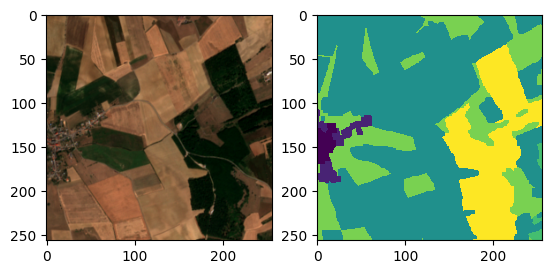

In [26]:
env = lmdb.open(fp_lmdb, readonly=True)
with env.begin() as txn:
    obj = txn.get(str(8156).encode())
    img_bytes, img_shape, lbl_bytes, lbl_shape, name = pickle.loads(obj)
    img = np.frombuffer(img_bytes, dtype=np.uint16).reshape(img_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
print(name.decode())
plt.figure()
plt.subplot(121)
img_show = img[[2,1,0]].transpose(1,2,0)
img_show = (img_show - np.min(img_show))/(np.max(img_show) - np.min(img_show))
plt.imshow(img_show)
plt.subplot(122)
plt.imshow(lbl.squeeze(), interpolation='none')

In [28]:
fp_ = '/p/project1/hai_dm4eo/liu_ch/data/SSL4EO-S2/downstream_lmdb_small_remove/osm_train_lmdb'
env = lmdb.open(fp_, readonly=True)
with env.begin() as txn:
    n = txn.stat()['entries']
n

19284

In [29]:
19284/4

4821.0